# 09 · El riesgo del día: intervalos, picos y anomalías

**Punto de partida.** Los modelos corrigen al MDA en los días normales, pero una parte desproporcionada del error está en pocos días: los de pico, cuando el MTR pasa de 3,000 MXN/MWh en alguna hora, y los que sorprenden al MDA. Antes de decidir qué modelo usar en qué día (notebook 10), hay que saber si esos días se pueden reconocer con lo que se sabe en *d−1*.

**Planteamiento.** Primero, intervalos en lugar de un solo número, que dicen cuánto confiar en el pronóstico. Después, si un clasificador puede anticipar los picos. Por último, qué son las anomalías (días en que el error del MDA se sale de lo normal), si son de Monclova o de todo el sistema, y si se pueden ver venir. Todo en desarrollo (julio a diciembre de 2024), salvo la descripción de las anomalías, que usa los datos de febrero a diciembre de 2024.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import features2 as f2, exp, referencias as rf, anomalias as an, picos, red, mapas, gb2
from pml.metrics import mae
R = rf.cargar()
c = f2.con_nodos(R.c0)                          # Monclova con los precios de los 64 nodos de la red
Y, X = R.Y, R.X
DEV, DIAS = exp.idx_dev(), exp.dias_eval(R.c0)
HASTA = pd.Timestamp('2024-12-31')              # la parte descriptiva no mira el test
HIST = pd.date_range(f2.TRAIN_START, HASTA)
m = R.mae                                       # MAE de desarrollo
tabla = lambda filas, archivo: (lambda T: (display(T), T.to_csv(REP / archivo)))(exp.comparar(Y, filas, X, registrar_como='nb11'))
c0, cb = R.c0, R.cb
Yt, Xt = f2._t(cb); SP = Yt - Xt               # el error del MDA en la escala del proyecto
CACHE = ROOT / 'data/processed/exp_cache'

## 1. Intervalos en lugar de un solo número

In [2]:
# Intervalos 10–90 con gradient boosting (pérdida de cuantiles), contra una referencia sencilla: el MDA más los cuantiles
# históricos de su error (solo días ya publicados). Se evalúan en todos los días, en días con pico y en días sin pico
QS = (0.1, 0.5, 0.9)
QB = pickle.loads((CACHE / 'q_Q_base_G0pG2.pkl').read_bytes())
emp = lambda q: pd.DataFrame({d: SP.loc[f2.TRAIN_START:d - pd.Timedelta(days=8)].quantile(q).values for d in DEV}, index=SP.columns).T
QQ = {'cuantiles condicionados al MDA': QB, 'referencia: MDA + cuantiles históricos del error': {q: emp(q) for q in QS}}
yp = picos.etiqueta(c0); dp = yp.loc[DEV]
rows = {}
for nombre, d in QQ.items():
    P = {q: f2.inv(d[q].loc[DEV] + Xt.loc[DEV], cb) for q in QS}
    for sub, ix in [('todos los días', DEV), ('días con pico', dp.index[dp == 1]), ('días sin pico', dp.index[dp == 0])]:
        a, l, h = Y.loc[ix].values, P[0.1].loc[ix].values, P[0.9].loc[ix].values
        rows[(nombre, sub)] = {'horas dentro del intervalo (meta 80%)': 100 * np.mean((a >= l) & (a <= h)), 'horas sobre el cuantil 90 (meta 10%)': 100 * np.mean(a > h),
                               'anchura mediana (MXN/MWh)': np.median(h - l), 'pérdida de cuantiles': np.mean([gb2.pinball(a, P[q].loc[ix].values, q) for q in QS])}
TQ = pd.DataFrame(rows).T.round(1); display(TQ); TQ.to_csv(REP / '09_intervalos_dev.csv')

horas dentro del intervalo (meta 80%)  \
cuantiles condicionados al MDA                   todos los días                                   80.9   
                                                 días con pico                                    72.8   
                                                 días sin pico                                    82.5   
referencia: MDA + cuantiles históricos del error todos los días                                   88.2   
                                                 días con pico                                    82.7   
                                                 días sin pico                                    89.4   

                                                                 horas sobre el cuantil 90 (meta 10%)  \
cuantiles condicionados al MDA                   todos los días                                   7.7   
                                                 días con pico                                   19.1   
                                                 días sin pico                                    5.4   
referencia: MDA + cuantiles históricos del error todos los días                                   5.0   
                                                 días con pico                                   13.2   
                                                 días sin pico                                    3.3   

                                                                 anchura mediana (MXN/MWh)  \
cuantiles condicionados al MDA                   todos los días                      411.9   
                                                 días con pico                       431.0   
                                                 días sin pico                       407.5   
referencia: MDA + cuantiles históricos del error todos los días                      823.4   
                                                 días con pico                       882.8   
                                                 días sin pico                       807.7   

                                                                 pérdida de cuantiles  
cuantiles condicionados al MDA                   todos los días                  79.0  
                                                 días con pico                  169.0  
                                                 días sin pico                   60.7  
referencia: MDA + cuantiles históricos del error todos los días                  93.5  
                                                 días con pico                  180.8  
                                                 días sin pico                   75.9

Los cuantiles condicionados al MDA contienen el MTR en 80.9% de las horas (la meta es 80%) con una anchura mediana de 412 MXN/MWh. La referencia sencilla (el MDA más los cuantiles históricos de su error) cubre 88.2% pero con intervalos del doble de ancho (823) y peor pérdida de cuantiles (93.5 contra 79.0). Pero en los días con pico los cuantiles cubren solo 72.8%, y el MTR pasa el cuantil 90 en 19.1% de las horas en lugar de 10%.

Condicionar al nivel del MDA ayuda a distinguir los días tranquilos de los nerviosos: el riesgo escala con el precio. En los días con pico, en cambio, se queda corto. Pero un intervalo no puede ensancharse en los días correctos si nadie sabe cuáles son.

A continuación se revisa si los picos se pueden anticipar.

## 2. ¿Se pueden anticipar los picos?

In [3]:
# Clasificador de días con pico (MTR > 3000 en alguna hora): ¿se pueden anticipar con lo que se sabe en d−1?
# Se comparan cuatro clasificadores, incluidas dos referencias simples
from pml import picos
yp = picos.etiqueta(c0)
print(f'días con pico: {int(yp.loc[f2.TRAIN_START:"2024-06-30"].sum())} antes del desarrollo, {int(yp.loc[DEV].sum())} en el desarrollo (de {len(DEV)})')
PK = {'climatología por mes': 'clima', 'solo el máximo del MDA': 'solo_mda', 'logístico con todo': 'logit', 'gradient boosting con todo': 'gb'}
PP = {k: picos.clasificar(c0, DEV, v) for k, v in PK.items()}
TP = pd.DataFrame({k: picos.evaluar(p, yp) for k, p in PP.items()}).T
TP = TP[['AUC', 'Brier', 'Brier_ref_tasa', 'aciertos_p50', 'falsas_p50']].rename(columns={
    'Brier_ref_tasa': 'Brier con la tasa real del periodo', 'aciertos_p50': 'picos con P > 0.5', 'falsas_p50': 'falsas alarmas con P > 0.5'})
display(TP.astype(float).round(3)); TP.to_csv(REP / '09_picos_clasificador_dev.csv')
# AUC de cada variable por separado, antes y durante el desarrollo: ¿la señal es estable?
from sklearn.metrics import roc_auc_score
RG = picos.rasgos(c0)
auc = pd.DataFrame({n: {col: roc_auc_score(yp.loc[s], RG.loc[s, col].fillna(0)) for col in ['mda_max', 'mda_eve', 'tmax_mty', 'picos_28d', 'sin1']}
                    for n, s in {'antes del desarrollo (mar–jun 2024)': slice('2024-03-05', '2024-06-30'), 'desarrollo (jul–dic 2024)': slice(f2.DEV_INI, f2.DEV_FIN)}.items()})
auc.index = ['máximo del MDA', 'MDA de 19 a 22 h', 'Tmax en Monterrey', 'frecuencia de picos (28 d)', 'estación (seno anual)']
print('AUC de cada feature por separado:'); display(auc.round(2))
# ¿El MDA anticipa los picos? Su máximo en días con y sin pico, y cuántas horas superó 3000
mx = pd.DataFrame({n: {'máximo del MDA, mediana en días con pico': c0.X.loc[s].max(axis=1)[yp.loc[s] == 1].median(),
                       'máximo del MDA, mediana en días sin pico': c0.X.loc[s].max(axis=1)[yp.loc[s] == 0].median(),
                       'horas con MDA > 3000': int((c0.X.loc[s] > 3000).values.sum())}
                   for n, s in {'antes del desarrollo': slice(f2.TRAIN_START, '2024-06-30'), 'desarrollo': slice(f2.DEV_INI, f2.DEV_FIN)}.items()})
display(mx.round(0))

días con pico: 52 antes del desarrollo, 31 en el desarrollo (de 184)


,AUC,Brier,Brier con la tasa real del periodo,picos con P > 0.5,falsas alarmas con P > 0.5
climatología por mes,0.553,0.159,0.14,0.0,0.0
solo el máximo del MDA,0.647,0.145,0.14,0.0,0.0
logístico con todo,0.477,0.151,0.14,1.0,2.0
gradient boosting con todo,0.642,0.141,0.14,2.0,4.0


AUC de cada feature por separado:


,antes del desarrollo (mar–jun 2024),desarrollo (jul–dic 2024)
máximo del MDA,0.81,0.69
MDA de 19 a 22 h,0.81,0.68
Tmax en Monterrey,0.82,0.60
frecuencia de picos (28 d),0.68,0.55
estación (seno anual),0.35,0.41


,antes del desarrollo,desarrollo
"máximo del MDA, mediana en días con pico",4232.0,1336.0
"máximo del MDA, mediana en días sin pico",828.0,894.0
horas con MDA > 3000,299.0,2.0


Ningún clasificador anticipa bien los picos del desarrollo. El mejor es el gradient boosting con AUC 0.64 y Brier 0.141, lo mismo que decir "17% de probabilidad todos los días" (0.140). El logístico queda peor que el azar (AUC 0.48). Las tablas muestran por qué: antes del desarrollo, en la ola de calor de abril a junio de 2024, el MDA marcaba más de 3,000 en 299 horas y el calor de Monterrey separaba bien los días (AUC 0.82). En el desarrollo el MDA superó 3,000 en solo 2 horas, y el máximo del MDA en un día con pico (mediana de 1,336) apenas supera al de un día normal (894).

Los picos de la segunda mitad de 2024 son sorpresas del tiempo real, sin aviso en el mercado del día anterior. Con 17 meses de historia, cada tipo de evento raro (ola de calor con MDA alto, alertas de CENACE, heladas de Texas) aparece una sola vez, y un modelo no puede aprender ni validar un patrón que vio una vez. Es una limitación del sistema, no del modelo.

Con MAE, el pronóstico óptimo es la mediana: aun sabiendo que hay 30% de probabilidad de pico, el punto no se movería. Un detector de picos sirve como alerta, no para corregir el pronóstico.

## 3. Las anomalías: los días en que el MTR se sale de lo normal

In [4]:
# Puntuación robusta de cada día y etiqueta de anomalía (después del hecho). Resumen y cruce con los días con pico
z = an.puntaje_expost(Y, X)
A = an.dias_anomalos(z).loc[HIST]
pico = picos.etiqueta(R.c0).reindex(HIST).fillna(0).astype(bool)
err = (Y - X).abs().mean(axis=1).reindex(HIST)                 # error absoluto medio del MDA en cada día
tab = {'días': len(A), 'días anómalos': int(A.anomalo.sum()), '  hacia arriba (MTR >> MDA)': int((A.tipo == 'arriba').sum()),
       '  hacia abajo (MTR << MDA)': int((A.tipo == 'abajo').sum()), '% de días anómalos': 100 * A.anomalo.mean(),
       'error medio del MDA, días anómalos': err[A.anomalo].mean(), 'error medio del MDA, días normales': err[~A.anomalo].mean(),
       '% del error del MDA en días anómalos': 100 * err[A.anomalo].sum() / err.sum()}
display(pd.Series(tab).round(1).to_frame('2024-02 a 2024-12'))
display(pd.crosstab(A.anomalo.map({True: 'anómalo', False: 'normal'}), pico.map({True: 'con pico', False: 'sin pico'}), margins=True, margins_name='total'))

,2024-02 a 2024-12
días,331.0
días anómalos,37.0
hacia arriba (MTR >> MDA),22.0
hacia abajo (MTR << MDA),15.0
% de días anómalos,11.2
"error medio del MDA, días anómalos",1448.3
"error medio del MDA, días normales",298.6
% del error del MDA en días anómalos,37.9


col_0,con pico,sin pico,total
anomalo,,,
anómalo,26,11,37
normal,57,237,294
total,83,248,331


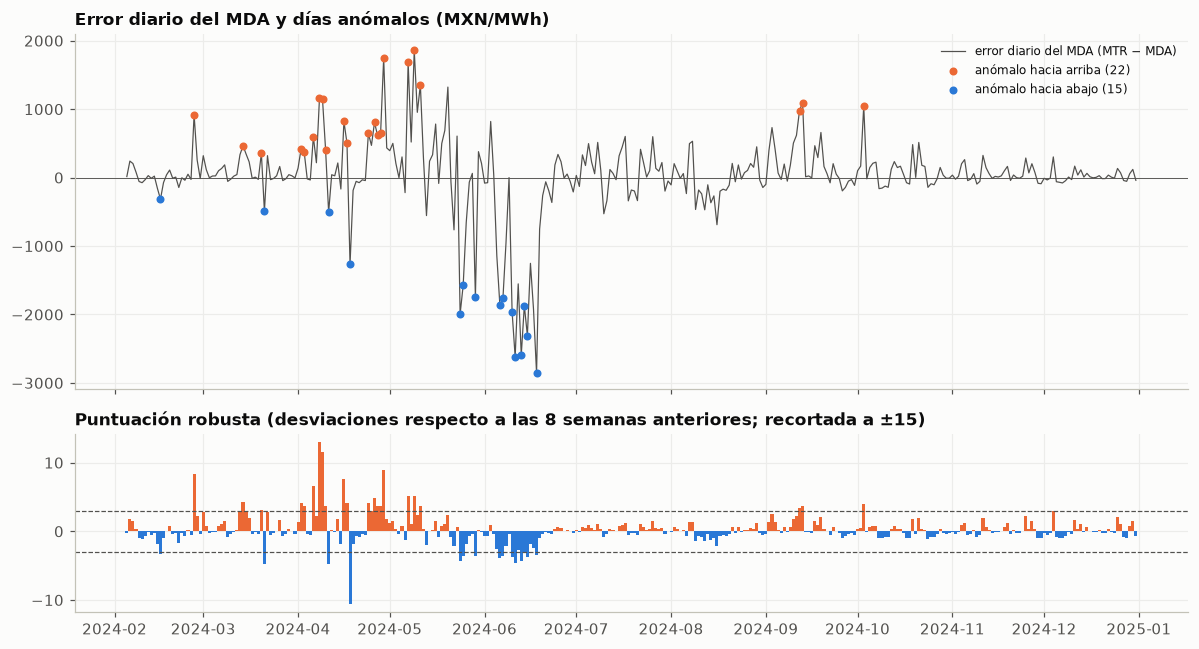

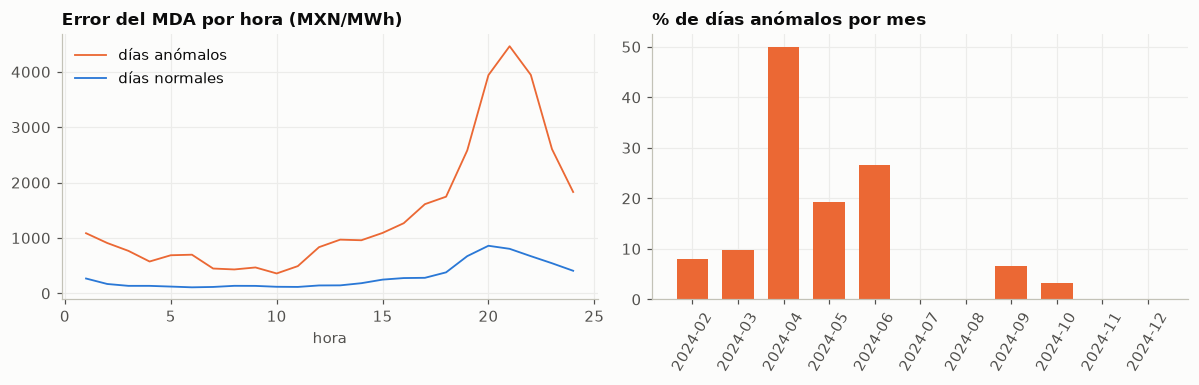

In [5]:
# Figuras: el error diario con los días anómalos marcados, su puntuación, el perfil horario y el % por mes
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
e = (Y - X).mean(axis=1).reindex(HIST)
axs[0].plot(e.index, e.values, color=ps.GRIS, lw=0.8, label='error diario del MDA (MTR − MDA)')
for t, col in (('arriba', ps.NARANJA), ('abajo', ps.AZUL)):
    k = A.index[A.tipo == t]
    axs[0].scatter(k, e.loc[k], color=col, s=18, zorder=3, label=f'anómalo hacia {t} ({len(k)})')
axs[0].axhline(0, color=ps.GRIS, lw=0.6); axs[0].legend(fontsize=8, loc='upper right')
axs[0].set_title('Error diario del MDA y días anómalos (MXN/MWh)')
axs[1].bar(A.index, A.z.clip(-15, 15), color=np.where(A.z > 0, ps.NARANJA, ps.AZUL), width=1)
axs[1].axhline(an.Z_ANOMALIA, color=ps.GRIS, ls='--', lw=0.8); axs[1].axhline(-an.Z_ANOMALIA, color=ps.GRIS, ls='--', lw=0.8)
axs[1].set_title('Puntuación robusta (desviaciones respecto a las 8 semanas anteriores; recortada a ±15)')
fig.tight_layout(); fig.savefig(FIG / '09_anomalias_tiempo.png'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
Sh = (Y - X).reindex(HIST)
axs[0].plot(range(1, 25), Sh[A.anomalo].abs().mean().values, color=ps.NARANJA, label='días anómalos')
axs[0].plot(range(1, 25), Sh[~A.anomalo].abs().mean().values, color=ps.AZUL, label='días normales')
axs[0].set_title('Error del MDA por hora (MXN/MWh)'); axs[0].set_xlabel('hora'); axs[0].legend()
mes = A.groupby(A.index.to_period('M')).anomalo.mean() * 100
axs[1].bar(mes.index.astype(str), mes.values, color=ps.NARANJA, width=0.7); axs[1].tick_params(axis='x', rotation=60)
axs[1].set_title('% de días anómalos por mes')
fig.tight_layout(); fig.savefig(FIG / '09_anomalias_hora_mes.png'); plt.show()

Entre febrero y diciembre de 2024 hay 37 días anómalos de 331 (11%): días cuyo error medio del MDA se aleja más de 3 desviaciones robustas de lo normal en las 8 semanas anteriores. En ellos el error medio es de 1,448 MXN/MWh, casi cinco veces el de un día normal (299), y cargan el 38% de todo el error del MDA. Van en las dos direcciones (22 con el MTR muy por encima del MDA, 15 muy por debajo) y se concentran en la primavera de 2024. De los 37, 26 tuvieron pico, pero 57 días con pico no fueron anómalos: el MDA ya venía alto y el MTR solo lo confirmó.

Lo difícil no son los picos en sí, sino las sorpresas: los días en que el MDA no vio venir lo que pasó. Esta definición usa el MTR del propio día, así que describe las anomalías pero no sirve para pronosticarlas.

## 4. ¿Son anomalías de toda la red o solo de Monclova?

en los días anómalos de Monclova, la fracción mediana de nodos que también lo fue: 0.78 | días en que más de la mitad de la red fue anómala: 31 de 37
en los días normales de Monclova, esa fracción mediana es 0.00


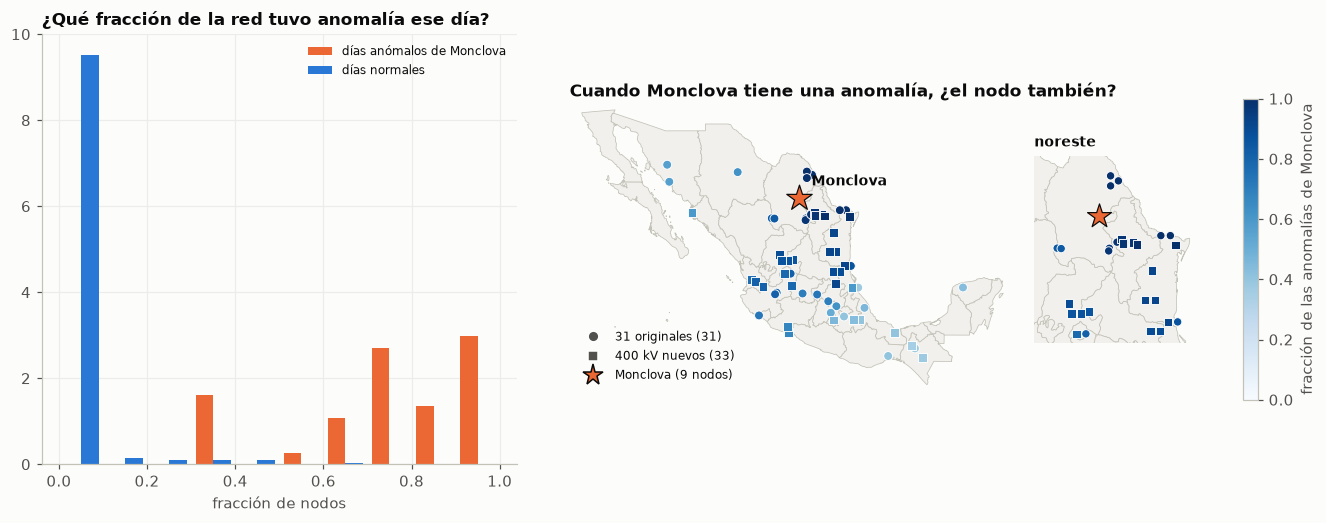

In [6]:
# Alcance en la red: la misma definición de anomalía aplicada a los 64 nodos. ¿Qué fracción acompaña a Monclova?
Ym, Xm = red.matrices_nodo('MTR', troncal=True), red.matrices_nodo('MDA', troncal=True)
alc = an.alcance_en_la_red(Ym, Xm, HIST)
ka = A.index[A.anomalo]
print(f'en los días anómalos de Monclova, la fracción mediana de nodos que también lo fue: {alc[ka].median():.2f} | '
      f'días en que más de la mitad de la red fue anómala: {(alc[ka] > 0.5).sum()} de {len(ka)}')
print(f'en los días normales de Monclova, esa fracción mediana es {alc[A.index[~A.anomalo]].median():.2f}')
marca = pd.DataFrame({n: an.dias_anomalos(an.puntaje_expost(Ym[n], Xm[n]))['anomalo'].reindex(HIST) for n in Ym})
acomp = marca.loc[ka].mean()                                   # P(nodo anómalo | Monclova anómala)
ub = red.ubicaciones()
fig = plt.figure(figsize=(12, 4.6))
a0 = fig.add_axes([0.0, 0.05, 0.36, 0.85]); a1 = fig.add_axes([0.40, 0.05, 0.42, 0.85]); a2 = fig.add_axes([0.84, 0.05, 0.16, 0.85])
a0.hist([alc[ka], alc[A.index[~A.anomalo]]], bins=np.linspace(0, 1, 11), color=[ps.NARANJA, ps.AZUL], label=['días anómalos de Monclova', 'días normales'], density=True)
a0.set_title('¿Qué fracción de la red tuvo anomalía ese día?'); a0.set_xlabel('fracción de nodos'); a0.legend(fontsize=8)
mapas.fondo(a1); sc = mapas.nodos(a1, ub, acomp, vmin=0, vmax=1, etiqueta=True, leyenda=True)
a1.set_title('Cuando Monclova tiene una anomalía, ¿el nodo también?')
mapas.fondo(a2, **mapas.NORESTE); mapas.nodos(a2, ub, acomp, vmin=0, vmax=1, tam=30); a2.set_title('noreste', fontsize=9)
fig.colorbar(sc, ax=[a1, a2], shrink=0.7, label='fracción de las anomalías de Monclova')
fig.savefig(FIG / '09_anomalias_red.png', bbox_inches='tight'); plt.show()

En los días anómalos de Monclova, la mediana de nodos de la red que también tuvo un día anómalo es 78% (en 31 de los 37 días, más de la mitad de la red). En los días normales esa fracción mediana es 0. El mapa muestra un gradiente geográfico: el carbón, Saltillo y Monterrey acompañan a Monclova en 97% a 100% de sus anomalías, Tamaulipas en 92%, el centro en 68% y el sureste y la península en alrededor de 40%.

Las anomalías de Monclova son del sistema: vienen de la energía nacional, no de la congestión local. Por eso entrenar con más nodos no ayuda a anticiparlas: los demás nodos tienen la misma sorpresa el mismo día.

## 5. ¿Se pueden anticipar con lo que se sabe en *d−1*?

,AUC anomalía,AUC pico,correlación con el error,la misma sin el nivel del MDA,error del 10% más riesgoso / resto
máximo del MDA,0.76,0.69,0.68,0.43,2.10
rareza del día,0.74,0.68,0.69,0.44,2.37
sincronía de la red,0.59,0.73,0.30,0.34,1.38
Isolation Forest,0.51,0.67,0.48,0.32,1.55
error de reconstrucción (PCA),0.68,0.56,0.30,0.01,1.44
clasificador de picos,0.85,0.64,0.53,0.26,2.11


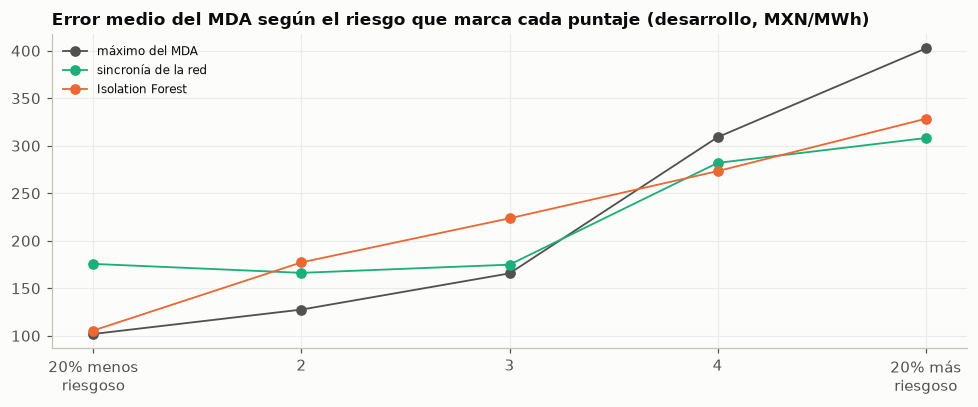

In [7]:
# Los seis puntajes de riesgo (todos con información de d−1) y qué tan bien ordenan los días de desarrollo
F, _ = f2.construir(an.replace_dias(c), ['G13', 'G14'])
inicio = f2.TRAIN_START + pd.Timedelta(days=35)                 # el detector necesita unas semanas de historia
PUNT = {'máximo del MDA': X.max(axis=1), 'rareza del día': F['rareza_dia'], 'sincronía de la red': F['red_sincronia28'],
        'Isolation Forest': an.puntaje_exante(c, pd.date_range(inicio, f2.TEST_FIN), 'isolation'),
        'error de reconstrucción (PCA)': an.puntaje_exante(c, pd.date_range(inicio, f2.TEST_FIN), 'pca'),
        'clasificador de picos': picos.clasificar(R.c0, pd.date_range(inicio + pd.Timedelta(days=28), f2.TEST_FIN), 'gb')}   # necesita 4 semanas más de historia
etiq = {'anomalía': an.dias_anomalos(z)['anomalo'].astype(int), 'pico': picos.etiqueta(R.c0)}
nivel = f2._t(R.c0)[1].mean(axis=1)
errd = (Y - X).abs().mean(axis=1)
SEP = pd.DataFrame({k: an.separacion(s.reindex(DEV), etiq, errd.reindex(DEV), nivel.reindex(DEV)) for k, s in PUNT.items()}).T
display(SEP.astype(float).round(2)); SEP.round(3).to_csv(REP / '09_detectores_dev.csv')

fig, ax = plt.subplots(figsize=(9, 3.8))
for k, col in zip(['máximo del MDA', 'sincronía de la red', 'Isolation Forest'], (ps.GRIS, ps.AQUA, ps.NARANJA)):
    s = PUNT[k].reindex(DEV)
    q = pd.qcut(s.rank(method='first'), 5, labels=False)
    ax.plot(range(1, 6), errd.reindex(DEV).groupby(q).mean().values, marker='o', color=col, label=k)
ax.set_xticks(range(1, 6), ['20% menos\nriesgoso', '2', '3', '4', '20% más\nriesgoso'])
ax.set_title('Error medio del MDA según el riesgo que marca cada puntaje (desarrollo, MXN/MWh)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '09_riesgo_vs_error.png'); plt.show()

Quienes mejor reconocen los días anómalos son el clasificador de picos (AUC 0.85) y el máximo del MDA (0.76); el Isolation Forest, que busca días "raros" sin ejemplos, queda en 0.51, casi al azar. Casi todo lo que detectan es el nivel del MDA: al descontarlo, la relación de los puntajes con el tamaño del error baja de 0.68 a 0.43 (máximo del MDA) y de 0.30 a 0.01 (PCA). El 10% de días con más riesgo según el puntaje tiene entre 1.4 y 2.4 veces más error que el resto.

Se puede decir "mañana es un día de más riesgo", sobre todo con el clasificador de picos y el nivel del MDA, pero esa señal ya la tienen los modelos, porque todos ven el MDA. Lo raro de un día anómalo ocurre en el tiempo real, no en lo que se sabe el día anterior.

## Decisiones

- Los intervalos de los cuantiles condicionados al MDA quedan como los intervalos del proyecto. Subestiman el riesgo en días con pico, limitación que se declara.
- Los picos casi no se pueden anticipar con lo que se sabe en *d−1*. El clasificador de picos y el máximo del MDA ordenan un poco el riesgo (sobre todo porque reflejan el nivel del MDA), y de ahí se saca un puntaje de riesgo para el siguiente notebook.
- Siguiente pregunta: ¿sirve ese puntaje para decidir qué modelo usar en cada día, y cómo se combinan los modelos? (notebook 10)